# Lab | NLP in Python

## Complete Submission

This notebook demonstrates a practical Natural Language Processing workflow in Python:

1. text normalization;
2. tokenization;
3. stop-word removal;
4. stemming;
5. word-frequency analysis;
6. n-grams;
7. Bag of Words;
8. TF-IDF;
9. cosine similarity;
10. a simple text-classification pipeline.

All examples are self-contained so the notebook can run without downloading external corpora.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfVectorizer
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Text normalization

Raw text often contains inconsistent capitalization, punctuation, URLs, numbers, and extra spaces.  
A normalization step makes later analysis more consistent.


In [2]:
sample_text = """
Natural Language Processing (NLP) is amazing! Visit https://example.com.
Python makes text-processing easier, and NLP models can learn from words, phrases, and sentences.
"""

def normalize_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

normalized = normalize_text(sample_text)

print("Original text:")
print(sample_text)
print("\nNormalized text:")
print(normalized)

Original text:

Natural Language Processing (NLP) is amazing! Visit https://example.com.
Python makes text-processing easier, and NLP models can learn from words, phrases, and sentences.


Normalized text:
natural language processing nlp is amazing visit python makes text processing easier and nlp models can learn from words phrases and sentences


## 2. Tokenization

Tokenization splits text into smaller units called **tokens**.  
For basic word-level NLP, tokens are usually words.


In [3]:
def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

tokens = tokenize(normalized)

print(tokens)
print("Number of tokens:", len(tokens))

['natural', 'language', 'processing', 'nlp', 'is', 'amazing', 'visit', 'python', 'makes', 'text', 'processing', 'easier', 'and', 'nlp', 'models', 'can', 'learn', 'from', 'words', 'phrases', 'and', 'sentences']
Number of tokens: 22


## 3. Stop-word removal

Stop words are very common terms such as *the*, *and*, *is*, and *to*.  
Depending on the task, removing them can reduce noise and emphasize more informative vocabulary.


In [4]:
stop_words = set(ENGLISH_STOP_WORDS)

filtered_tokens = [
    token for token in tokens
    if token not in stop_words
]

print("Before:", tokens)
print("\nAfter stop-word removal:", filtered_tokens)

Before: ['natural', 'language', 'processing', 'nlp', 'is', 'amazing', 'visit', 'python', 'makes', 'text', 'processing', 'easier', 'and', 'nlp', 'models', 'can', 'learn', 'from', 'words', 'phrases', 'and', 'sentences']

After stop-word removal: ['natural', 'language', 'processing', 'nlp', 'amazing', 'visit', 'python', 'makes', 'text', 'processing', 'easier', 'nlp', 'models', 'learn', 'words', 'phrases', 'sentences']


## 4. Stemming

Stemming reduces related word forms to a common stem.  
For example, *processing*, *processed*, and *processes* can be reduced toward the same root form.

The Porter stemmer is rule-based and does not require any external NLTK corpus.


In [5]:
stemmer = PorterStemmer()

stemmed_tokens = [stemmer.stem(token) for token in filtered_tokens]

comparison = pd.DataFrame({
    "token": filtered_tokens,
    "stem": stemmed_tokens
})

comparison

,token,stem
0,natural,natur
1,language,languag
2,processing,process
3,nlp,nlp
4,amazing,amaz
5,visit,visit
6,python,python
7,makes,make
8,text,text
9,processing,process


## 5. Word-frequency analysis

Frequency analysis is one of the simplest ways to understand what vocabulary dominates a document or corpus.


In [6]:
corpus = [
    "Python is a popular language for data science and machine learning.",
    "Natural language processing helps computers understand human language.",
    "Python libraries make natural language processing easier.",
    "Machine learning models can classify text and predict sentiment.",
    "Text preprocessing includes tokenization normalization and feature extraction."
]

all_tokens = []

for document in corpus:
    clean = normalize_text(document)
    words = tokenize(clean)
    words = [word for word in words if word not in stop_words]
    all_tokens.extend(words)

frequencies = Counter(all_tokens)

freq_df = pd.DataFrame(
    frequencies.most_common(),
    columns=["word", "frequency"]
)

freq_df.head(15)

,word,frequency
0,language,4
1,python,2
2,machine,2
3,learning,2
4,natural,2
5,processing,2
6,text,2
7,popular,1
8,data,1
9,science,1


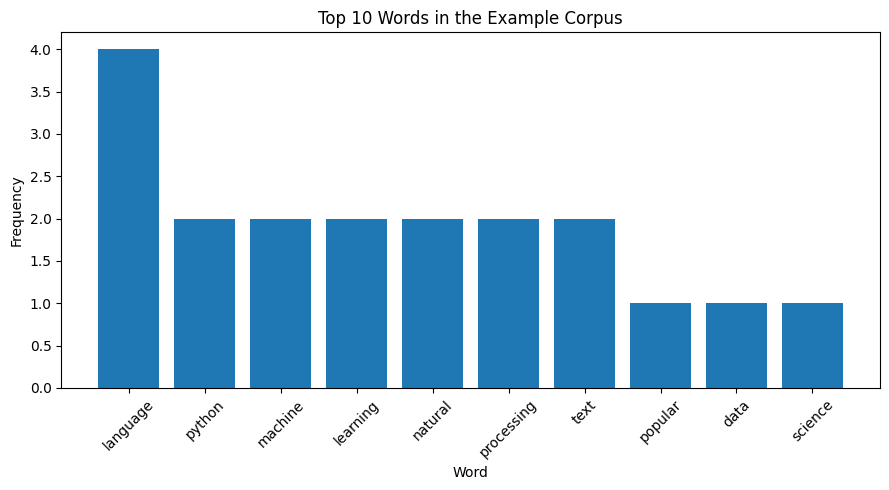

In [7]:
top_words = freq_df.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top_words["word"], top_words["frequency"])
plt.title("Top 10 Words in the Example Corpus")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. N-grams

An **n-gram** is a sequence of `n` consecutive tokens:

- unigram: one word;
- bigram: two consecutive words;
- trigram: three consecutive words.

N-grams preserve some local word order that a simple list of individual words loses.


In [8]:
def make_ngrams(tokens, n):
    return [
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    ]

example_tokens = tokenize("natural language processing with python is useful")

print("Unigrams:", make_ngrams(example_tokens, 1))
print("Bigrams:", make_ngrams(example_tokens, 2))
print("Trigrams:", make_ngrams(example_tokens, 3))

Unigrams: [('natural',), ('language',), ('processing',), ('with',), ('python',), ('is',), ('useful',)]
Bigrams: [('natural', 'language'), ('language', 'processing'), ('processing', 'with'), ('with', 'python'), ('python', 'is'), ('is', 'useful')]
Trigrams: [('natural', 'language', 'processing'), ('language', 'processing', 'with'), ('processing', 'with', 'python'), ('with', 'python', 'is'), ('python', 'is', 'useful')]


## 7. Bag of Words

Bag of Words represents each document using counts of vocabulary terms.  
It ignores most word order but creates numeric features that machine-learning algorithms can use.


In [9]:
count_vectorizer = CountVectorizer(
    stop_words="english"
)

bow_matrix = count_vectorizer.fit_transform(corpus)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)

print("Bag-of-Words matrix shape:", bow_df.shape)
bow_df

Bag-of-Words matrix shape: (5, 27)


,classify,computers,data,easier,extraction,feature,helps,human,includes,language,...,popular,predict,preprocessing,processing,python,science,sentiment,text,tokenization,understand
0,0,0,1,0,0,0,0,0,0,1,...,1,0,0,0,1,1,0,0,0,0
1,0,1,0,0,0,0,1,1,0,2,...,0,0,0,1,0,0,0,0,0,1
2,0,0,0,1,0,0,0,0,0,1,...,0,0,0,1,1,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,1,1,0,0
4,0,0,0,0,1,1,0,0,1,0,...,0,0,1,0,0,0,0,1,1,0


## 8. TF-IDF

TF-IDF gives larger weights to words that are important in a document but not common across every document.

- **TF** = term frequency;
- **IDF** = inverse document frequency.

This often produces more informative features than raw counts.


In [10]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english"
)

tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("TF-IDF matrix shape:", tfidf_df.shape)
tfidf_df.round(3)

TF-IDF matrix shape: (5, 27)


,classify,computers,data,easier,extraction,feature,helps,human,includes,language,...,popular,predict,preprocessing,processing,python,science,sentiment,text,tokenization,understand
0,0.00,0.000,0.43,0.00,0.000,0.000,0.000,0.000,0.000,0.288,...,0.43,0.00,0.000,0.000,0.347,0.43,0.00,0.000,0.000,0.000
1,0.00,0.375,0.00,0.00,0.000,0.000,0.375,0.375,0.000,0.503,...,0.00,0.00,0.000,0.303,0.000,0.00,0.00,0.000,0.000,0.375
2,0.00,0.000,0.00,0.43,0.000,0.000,0.000,0.000,0.000,0.288,...,0.00,0.00,0.000,0.347,0.347,0.00,0.00,0.000,0.000,0.000
3,0.41,0.000,0.00,0.00,0.000,0.000,0.000,0.000,0.000,0.000,...,0.00,0.41,0.000,0.000,0.000,0.00,0.41,0.331,0.000,0.000
4,0.00,0.000,0.00,0.00,0.388,0.388,0.000,0.000,0.388,0.000,...,0.00,0.00,0.388,0.000,0.000,0.00,0.00,0.313,0.388,0.000


## 9. Document similarity

After documents are converted into TF-IDF vectors, cosine similarity can compare their direction in vector space.

A score near:

- `1` means very similar;
- `0` means little similarity.


In [11]:
similarity_matrix = cosine_similarity(tfidf_matrix)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=[f"doc_{i+1}" for i in range(len(corpus))],
    columns=[f"doc_{i+1}" for i in range(len(corpus))]
)

similarity_df.round(3)

,doc_1,doc_2,doc_3,doc_4,doc_5
doc_1,1.000,0.145,0.204,0.230,0.000
doc_2,0.145,1.000,0.355,0.000,0.000
doc_3,0.204,0.355,1.000,0.000,0.000
doc_4,0.230,0.000,0.000,1.000,0.103
doc_5,0.000,0.000,0.000,0.103,1.000


In [12]:
# Find the most similar pair of different documents.
sim = similarity_matrix.copy()
np.fill_diagonal(sim, -1)

i, j = np.unravel_index(np.argmax(sim), sim.shape)

print("Most similar pair:")
print(f"Document {i+1}: {corpus[i]}")
print(f"Document {j+1}: {corpus[j]}")
print(f"Cosine similarity: {similarity_matrix[i, j]:.3f}")

Most similar pair:
Document 2: Natural language processing helps computers understand human language.
Document 3: Python libraries make natural language processing easier.
Cosine similarity: 0.355


## 10. Simple sentiment-classification example

A standard NLP machine-learning pipeline is:

1. collect labeled text;
2. convert text to numeric features;
3. split into training and test data;
4. train a classifier;
5. evaluate it on unseen examples.

The following self-contained example uses TF-IDF features and logistic regression.


In [13]:
sentiment_data = pd.DataFrame({
    "text": [
        "I love this product",
        "This was an excellent purchase",
        "The service was fantastic",
        "I am very happy with the result",
        "The movie was wonderful",
        "What a great experience",
        "I strongly recommend this",
        "The quality is really good",
        "I hate this product",
        "This was a terrible purchase",
        "The service was awful",
        "I am very disappointed",
        "The movie was boring",
        "What a bad experience",
        "I would not recommend this",
        "The quality is really poor",
        "Absolutely loved it",
        "Very pleasant and enjoyable",
        "It exceeded my expectations",
        "I am satisfied with it",
        "Absolutely hated it",
        "Very unpleasant and frustrating",
        "It failed my expectations",
        "I am dissatisfied with it"
    ],
    "sentiment": [
        1,1,1,1,1,1,1,1,
        0,0,0,0,0,0,0,0,
        1,1,1,1,
        0,0,0,0
    ]
})

sentiment_data.head()

,text,sentiment
0,I love this product,1
1,This was an excellent purchase,1
2,The service was fantastic,1
3,I am very happy with the result,1
4,The movie was wonderful,1


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    sentiment_data["text"],
    sentiment_data["sentiment"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=sentiment_data["sentiment"]
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LogisticRegression(
    random_state=RANDOM_STATE
)

model.fit(X_train_tfidf, y_train)

predictions = model.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, predictions, digits=3))

Accuracy: 0.167

Classification report:
              precision    recall  f1-score   support

           0      0.250     0.333     0.286         3
           1      0.000     0.000     0.000         3

    accuracy                          0.167         6
   macro avg      0.125     0.167     0.143         6
weighted avg      0.125     0.167     0.143         6



In [15]:
cm = confusion_matrix(y_test, predictions)

print("Confusion matrix:")
print(cm)

results = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": predictions
})

results

Confusion matrix:
[[1 2]
 [3 0]]


,text,actual,predicted
0,I would not recommend this,0,1
1,I am satisfied with it,1,0
2,The quality is really good,1,0
3,The service was fantastic,1,0
4,I am very disappointed,0,1
5,The quality is really poor,0,0


## 11. Reusable NLP preprocessing function

The steps above can be combined into one reusable preprocessing function.


In [16]:
def preprocess_text(text, remove_stopwords=True, stem=True):
    # Normalize
    text = normalize_text(text)

    # Tokenize
    words = tokenize(text)

    # Remove stop words
    if remove_stopwords:
        words = [
            word for word in words
            if word not in stop_words
        ]

    # Stem
    if stem:
        words = [
            stemmer.stem(word)
            for word in words
        ]

    return words

test_sentence = (
    "The programmers were processing several documents "
    "using powerful Python libraries."
)

print(preprocess_text(test_sentence))

['programm', 'process', 'document', 'use', 'power', 'python', 'librari']


## 12. Key concepts and conclusions

### Tokenization
Breaks text into units such as words or sentences.

### Stop words
Very frequent words that may add little discriminative information in some NLP tasks.

### Stemming
Uses rules to shorten related words to stems. A stem is not guaranteed to be a valid dictionary word.

### Bag of Words
Represents documents using vocabulary counts and generally ignores word order.

### TF-IDF
Weights terms by how important they are to one document relative to the whole corpus.

### N-grams
Capture short sequences of words and therefore preserve more local context than isolated unigrams.

### Cosine similarity
Measures similarity between document vectors based on their orientation rather than raw magnitude.

### Text classification
Transforms text into numeric features and trains a supervised model to predict a label such as topic or sentiment.

Overall, NLP preprocessing converts unstructured language into structured representations that can be analyzed statistically or used by machine-learning models.
